### Алгоритмы DQN и Double DQN в средах Acrobot-v1 и LunarLander-v3

<img src="images/dqn.jpg" width="60%" alt="dqn">

In [1]:
import random
import time
from collections import deque
from typing import Dict, List, Tuple
from IPython import display

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import torch
import torch.nn as nn
import torch.optim as optim

sns.set_theme(style="whitegrid")
plt.rcParams['text.latex.preamble'] = r'\usepackage{amsmath}\usepackage{amsfonts}'
plt.rcParams.update({
    'text.usetex': True,
    'font.family': 'serif',
    'axes.labelsize': 12,
    'axes.titlesize': 13,
    'legend.fontsize': 10,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10
})
%config InlineBackend.figure_format = 'retina'

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

In [2]:
class QNetwork(nn.Module):
    """
    Нейронная сеть для аппроксимации функции Q(s, a; \theta).
    Принимает вектор состояния s, возвращает вектор ценностей действий.
    """
    def __init__(self, state_dim: int, action_dim: int, hidden_dim: int = 128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(state_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, action_dim)
        )

    def forward(self, state: torch.Tensor) -> torch.Tensor:
        return self.net(state)


class ReplayBuffer:
    """
    Циклический буфер памяти фиксированной ёмкости (FIFO)
    """
    def __init__(self, capacity: int):
        self.buffer = deque(maxlen=capacity)  # Двусторонняя очередь

    def push(self, state: np.ndarray, action: int, reward: float, next_state: np.ndarray, done: bool):
        self.buffer.append((state, action, reward, next_state, done))

    def sample(self, batch_size: int) -> Tuple[torch.Tensor, ...]:
        batch = random.sample(self.buffer, batch_size)
        states, actions, rewards, next_states, dones = zip(*batch)

        return (
            torch.tensor(np.array(states), dtype=torch.float32),
            torch.tensor(actions, dtype=torch.int64).unsqueeze(1),
            torch.tensor(rewards, dtype=torch.float32).unsqueeze(1),
            torch.tensor(np.array(next_states), dtype=torch.float32),
            torch.tensor(dones, dtype=torch.float32).unsqueeze(1)
        )

    def __len__(self) -> int:
        return len(self.buffer)


class DQNAgent:
    """
    Реализует обучение алгоритмов DQN и Double DQN.
    """
    def __init__(
        self,
        state_dim: int,
        action_dim: int,
        is_double: bool = False,
        lr: float = 1e-3,
        gamma: float = 0.99,
        buffer_capacity: int = 50_000,
        batch_size: int = 64,
        tau: float = 0.005  # Коэффициент экспоненциального сглаживания (Polyak update)
    ):
        self.action_dim = action_dim
        self.is_double = is_double
        self.gamma = gamma
        self.batch_size = batch_size
        self.tau = tau

        # Инициализация архитектуры
        self.policy_net = QNetwork(state_dim, action_dim)
        self.target_net = QNetwork(state_dim, action_dim)
        self.target_net.load_state_dict(self.policy_net.state_dict())
        self.target_net.eval()

        self.optimizer = optim.Adam(self.policy_net.parameters(), lr=lr)
        self.loss_fn = nn.SmoothL1Loss()  # Функция потерь Хьюбера
        self.buffer = ReplayBuffer(buffer_capacity)

    def select_action(self, state: np.ndarray, epsilon: float = 0.0) -> int:
        """Эпсилон-жадный выбор действия относительно текущих оценок основной сети."""
        if random.random() < epsilon:
            return random.randrange(self.action_dim)
        with torch.no_grad():
            s = torch.tensor(state, dtype=torch.float32).unsqueeze(0)
            return int(self.policy_net(s).argmax(dim=1).item())

    def update(self) -> float:
        """Один шаг градиентной оптимизации по случайному мини-батчу."""
        if len(self.buffer) < self.batch_size:
            return 0.0

        b_states, b_actions, b_rewards, b_next_states, b_dones = self.buffer.sample(self.batch_size)

        # Текущая оценка выбранного действия Q(s_t, a_t; \theta)
        q_eval = self.policy_net(b_states).gather(1, b_actions)

        # Вычисление целевого значения TD-ошибки
        with torch.no_grad():
            if self.is_double:
                # Double DQN: разделение выбора жадного действия и его оценки
                # a^* = argmax_{a'} Q(s_{t+1}, a'; \theta)
                best_actions = self.policy_net(b_next_states).argmax(dim=1, keepdim=True)
                # y = r + \gamma * Q(s_{t+1}, a^*; \bar{\theta})
                q_next = self.target_net(b_next_states).gather(1, best_actions)
            else:
                # Стандартный DQN: оператор максимума целиком на целевой сети
                # y = r + \gamma * \max_{a'} Q(s_{t+1}, a'; \bar{\theta})
                q_next = self.target_net(b_next_states).max(dim=1, keepdim=True)[0] #!

            td_target = b_rewards + self.gamma * (1.0 - b_dones) * q_next

        # Минимизация функции потерь Хьюбера
        loss = self.loss_fn(q_eval, td_target)

        self.optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(self.policy_net.parameters(), max_norm=10.0)
        self.optimizer.step()

        # Мягкая синхронизация весов целевой сети: \bar{\theta} <- \tau * \theta + (1 - \tau) * \bar{\theta}
        for target_param, param in zip(self.target_net.parameters(), self.policy_net.parameters()):
            target_param.data.copy_(self.tau * param.data + (1.0 - self.tau) * target_param.data)

        return float(loss.item())

In [3]:
# Конфигурация экспериментов по средам
experiments_config = [
    {
        "env_id": "Acrobot-v1",
        "episodes": 150,
        "eps_decay": 0.98,
        "window": 20
    },
    {
        "env_id": "LunarLander-v3",
        "episodes": 200,
        "eps_decay": 0.985,
        "window": 25
    }
]

def train_agent(
    env_name: str,
    agent_name: str,
    agent: DQNAgent,
    episodes: int = 250,
    epsilon_start: float = 1.0,
    epsilon_end: float = 0.02,
    epsilon_decay: float = 0.99
) -> Dict[str, any]:
    """
    Обучающий цикл.
    """
    env = gym.make(env_name)
    epsilon = epsilon_start

    rewards_history = []

    t_start = time.time()
    print(agent_name)

    for ep in range(episodes):
        state, info = env.reset()
        episode_reward = 0.0
        done = False

        while not done:
            action = agent.select_action(state, epsilon)
            next_state, reward, terminated, truncated, info = env.step(action)
            done = terminated or truncated

            agent.buffer.push(state, action, reward, next_state, terminated)
            state = next_state
            episode_reward += reward

            agent.update()

        epsilon = max(epsilon_end, epsilon * epsilon_decay)
        rewards_history.append(episode_reward)

        if (ep + 1) % 25 == 0:
            avg_r = np.mean(rewards_history[-25:])
            t_elapsed = time.time() - t_start
            print(
                f"Эпизод {ep + 1:3d}/{episodes} | "
                f"Время: {t_elapsed:5.1f} с | "
                f"Средняя награда (25 эп.): {avg_r:6.1f}"
            )

    total_time = time.time() - t_start
    env.close()
    print(f"{agent_name} завершён за {total_time:.1f} с.\n")

    return {
        "name": agent_name,
        "rewards": np.array(rewards_history),
        "time": total_time,
        "agent": agent
    }

Простая эвристическая стратегия: Acrobot-v1


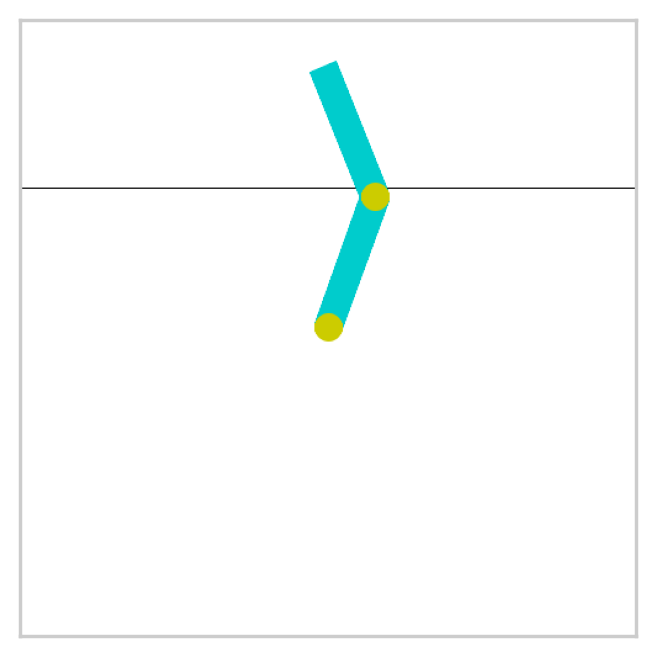

G_0 = -162.00 | шагов: 163

Простая эвристическая стратегия: LunarLander-v3


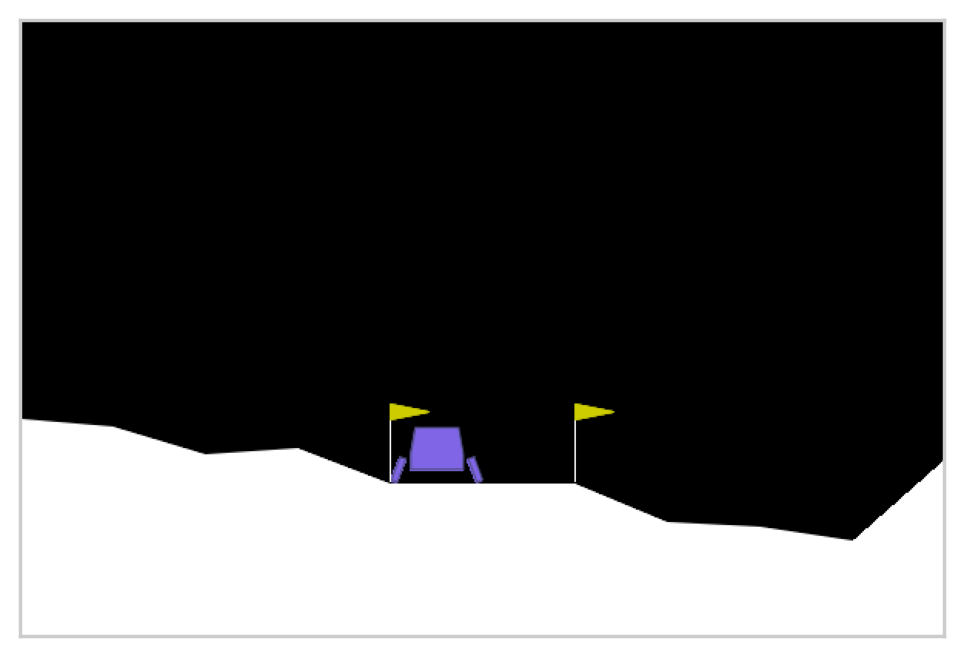

G_0 = 258.07 | шагов: 225



In [4]:
# Демонстрация сред с простыми эвристическими стратегиями
def heuristic_action(env_id, state):
    if env_id == "Acrobot-v1":
        # Раскачивание: переключать момент в зависимости от фазы движения.
        phase = state[4] + 0.5 * state[5]
        return 2 if phase >= 0 else 0

    if env_id == "LunarLander-v3":
        # Корректировать наклон и тормозить вертикальное падение.
        x, y, vx, vy, angle, angular_velocity, left_leg, right_leg = state
        angle_target = np.clip(0.5 * x + vx, -0.4, 0.4)
        hover_target = 0.55 * abs(x)
        angle_correction = 0.5 * (angle_target - angle) - angular_velocity
        hover_correction = 0.5 * (hover_target - y) - 0.5 * vy

        if hover_correction > abs(angle_correction) and hover_correction > 0.05:
            return 2  # Основной двигатель
        if angle_correction < -0.05:
            return 3  # Боковой двигатель
        if angle_correction > 0.05:
            return 1  # Боковой двигатель
        return 0  # Двигатели выключены


for env_id in ["Acrobot-v1", "LunarLander-v3"]:
    print(f"Простая эвристическая стратегия: {env_id}")
    
    # Меняем режим рендеринга на rgb_array
    env = gym.make(env_id, render_mode="rgb_array")
    state, info = env.reset(seed=SEED)
    episode_return = 0.0  # G_0
    episode_steps = 0

    # Создаем фигуру для рисования в Jupyter
    fig, ax = plt.subplots(figsize=(6, 4))
    # Делаем первый снимок и убираем оси
    img = ax.imshow(env.render())
    ax.set_xticks([])
    ax.set_yticks([])

    display_handle = display.display(fig, display_id=True)

    for _ in range(1000):
        action = heuristic_action(env_id, state)
        state, reward, terminated, truncated, info = env.step(action)
        episode_return += reward
        episode_steps += 1
        
        img.set_data(env.render())
        display_handle.update(fig)
        
        if terminated or truncated:
            break
    
    plt.close(fig)
    env.close()
    print(f"G_0 = {episode_return:.2f} | шагов: {episode_steps}\n")

Acrobot-v1
Vanilla DQN
Эпизод  25/150 | Время:  23.5 с | Средняя награда (25 эп.): -426.4
Эпизод  50/150 | Время:  34.2 с | Средняя награда (25 эп.): -171.1
Эпизод  75/150 | Время:  42.3 с | Средняя награда (25 эп.): -127.5
Эпизод 100/150 | Время:  49.9 с | Средняя награда (25 эп.): -118.6
Эпизод 125/150 | Время:  55.9 с | Средняя награда (25 эп.):  -97.0
Эпизод 150/150 | Время:  61.8 с | Средняя награда (25 эп.):  -93.6
Vanilla DQN завершён за 61.8 с.

Double DQN
Эпизод  25/150 | Время:  27.3 с | Средняя награда (25 эп.): -455.1
Эпизод  50/150 | Время:  39.6 с | Средняя награда (25 эп.): -195.4
Эпизод  75/150 | Время:  48.0 с | Средняя награда (25 эп.): -133.1
Эпизод 100/150 | Время:  55.1 с | Средняя награда (25 эп.): -110.2
Эпизод 125/150 | Время:  62.0 с | Средняя награда (25 эп.): -103.7
Эпизод 150/150 | Время:  68.7 с | Средняя награда (25 эп.):  -99.6
Double DQN завершён за 68.7 с.

LunarLander-v3
Vanilla DQN
Эпизод  25/200 | Время:   6.0 с | Средняя награда (25 эп.): -149.7
Эпи

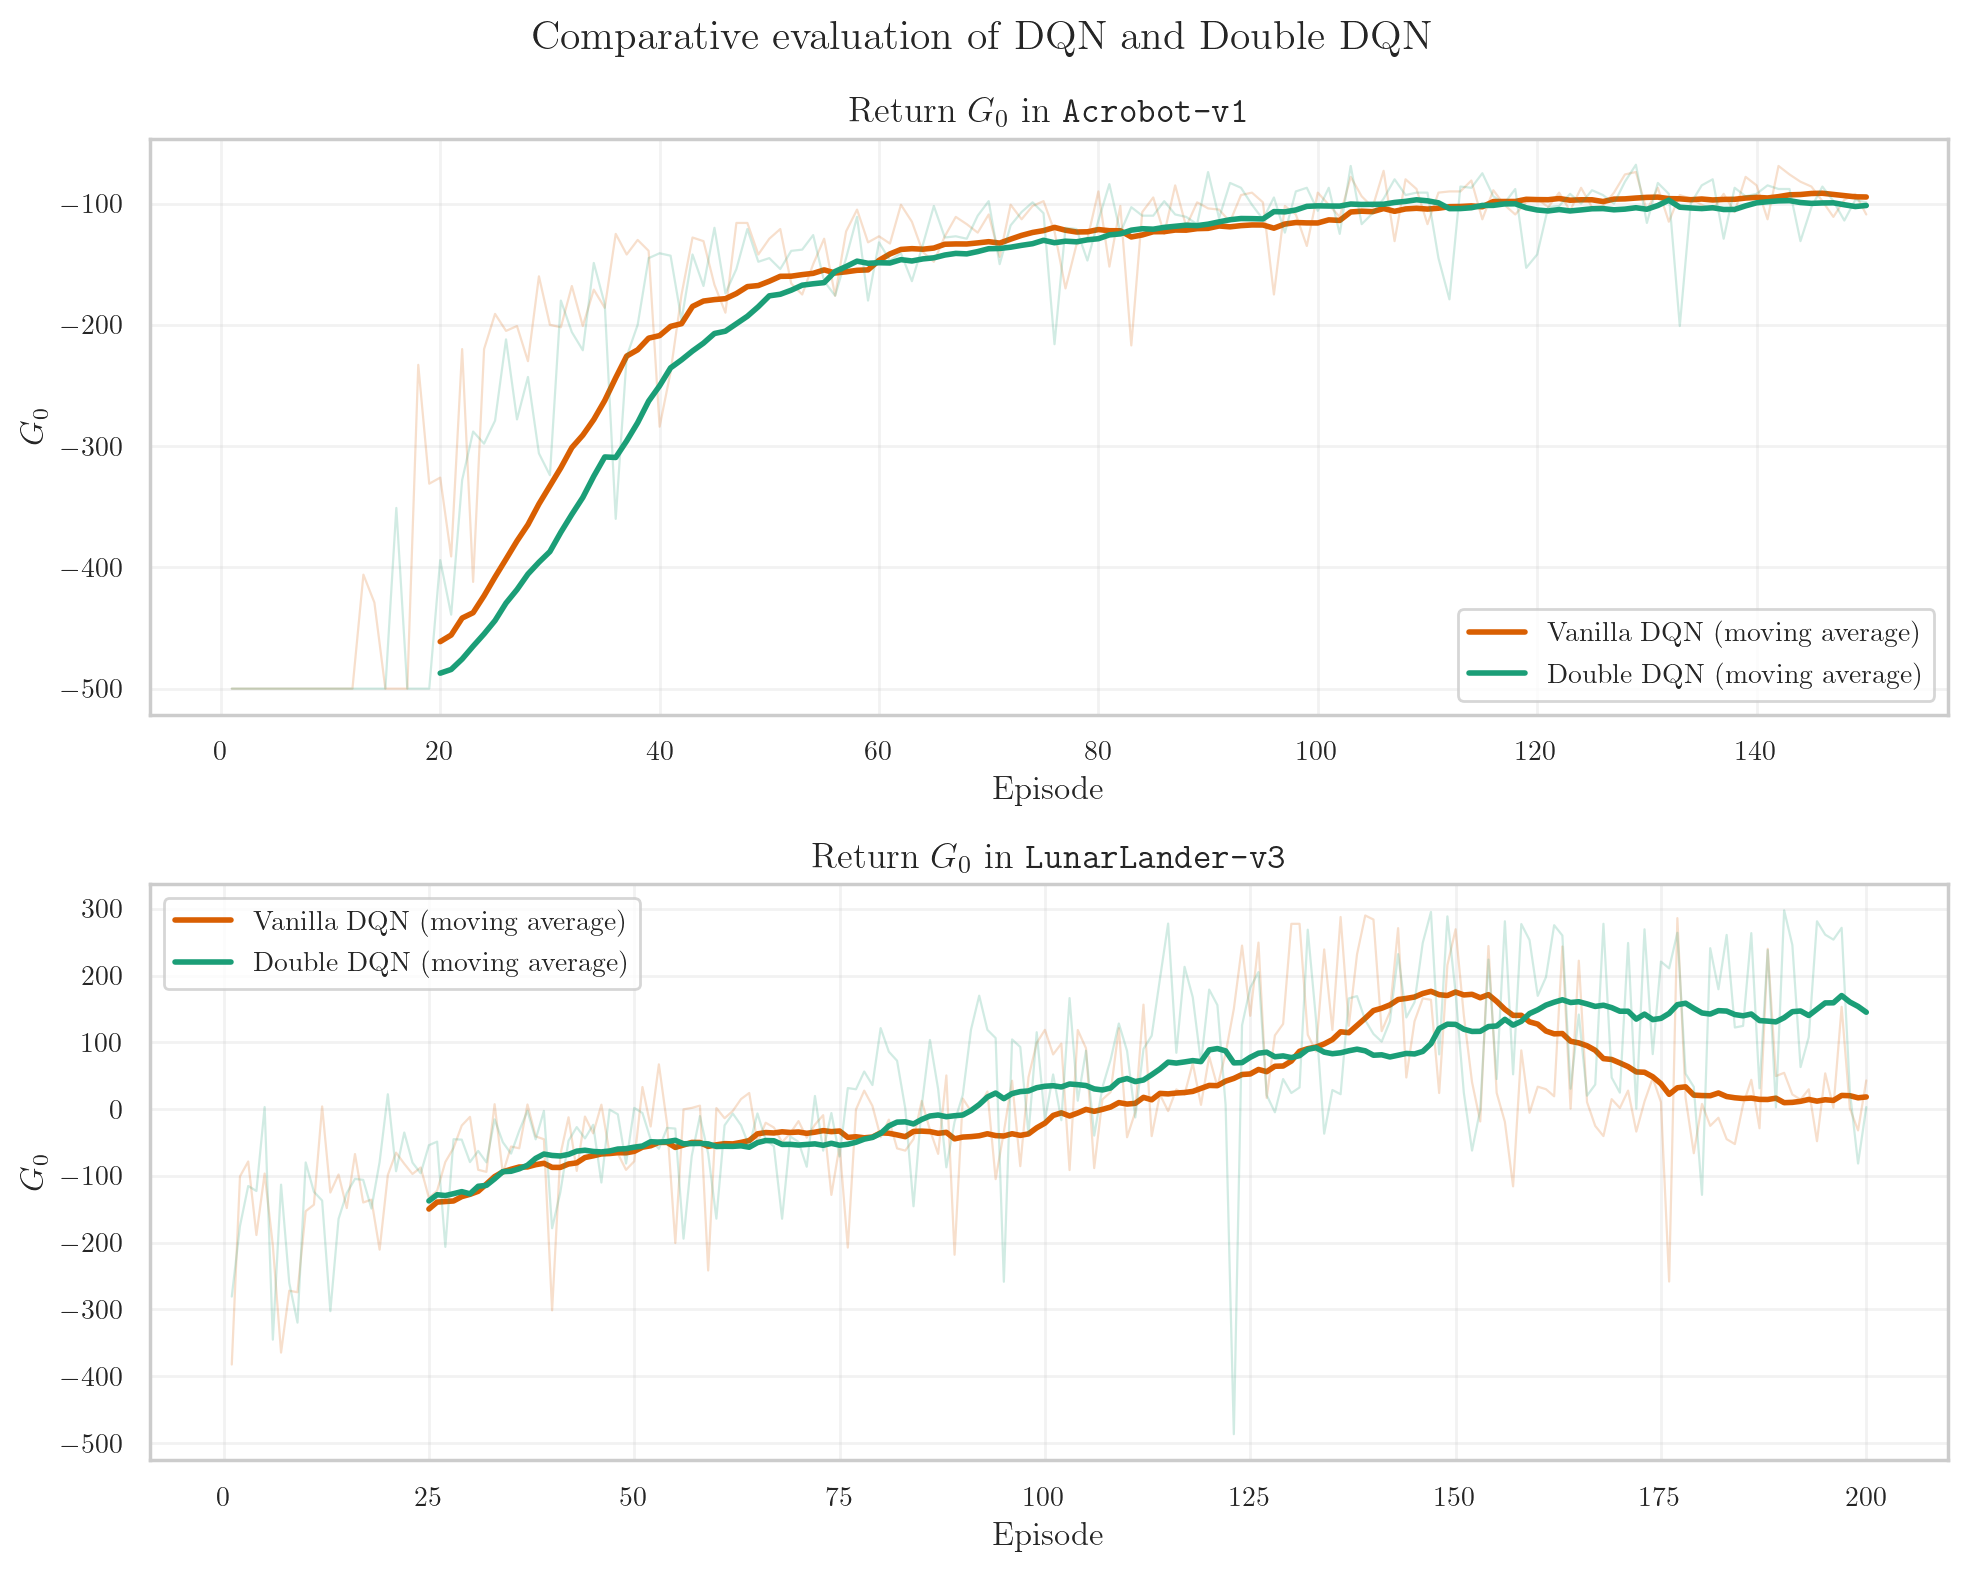

In [5]:
all_env_results = {}

for cfg in experiments_config:
    env_id = cfg["env_id"]
    
    print(f"{'='*70}\n{env_id}\n{'='*70}")

    temp_env = gym.make(env_id)
    s_dim = temp_env.observation_space.shape[0]
    a_dim = temp_env.action_space.n
    temp_env.close()

    # Инициализация агентов
    agents_dict = {
        "Vanilla DQN": DQNAgent(s_dim, a_dim, is_double=False),
        "Double DQN": DQNAgent(s_dim, a_dim, is_double=True)
    }

    # Обучение агентов
    env_res = []
    for a_name, a_obj in agents_dict.items():
        res = train_agent(
            env_name=env_id,
            agent_name=a_name,
            agent=a_obj,
            episodes=cfg["episodes"],
            epsilon_decay=cfg["eps_decay"]
        )
        env_res.append(res)

    all_env_results[env_id] = (env_res, cfg["window"])


fig, axes = plt.subplots(len(all_env_results), 1, figsize=(10, 8))
colors = ["#d95f02", "#1b9e77"]  # Vanilla DQN, Double DQN

for ax, (env_id, (results, window)) in zip(axes, all_env_results.items()):
    for idx, res in enumerate(results):
        rewards = res["rewards"]
        name = res["name"]
        color = colors[idx]

        # Награда каждого отдельного эпизода
        ax.plot(np.arange(1, len(rewards) + 1), rewards, color=color, alpha=0.2, lw=0.8)

        # Скользящее среднее награды
        if len(rewards) >= window:
            moving_avg = np.convolve(rewards, np.ones(window) / window, mode="valid")
            ax.plot(np.arange(window, len(rewards) + 1), moving_avg, color=color, lw=2.0, label=f"{name} (moving average)")
        else:
            ax.plot(np.arange(1, len(rewards) + 1), rewards, color=color, lw=1.5, label=name)

    ax.set_title(rf"Return $G_0$ in \texttt{{{env_id}}}")
    ax.set_xlabel(r"Episode")
    ax.set_ylabel(r"$G_0$")
    ax.legend(loc="best")
    ax.grid(alpha=0.25)

fig.suptitle("Comparative evaluation of DQN and Double DQN", fontsize=15)
fig.tight_layout()
plt.show()

После обучения: Acrobot-v1 | Vanilla DQN


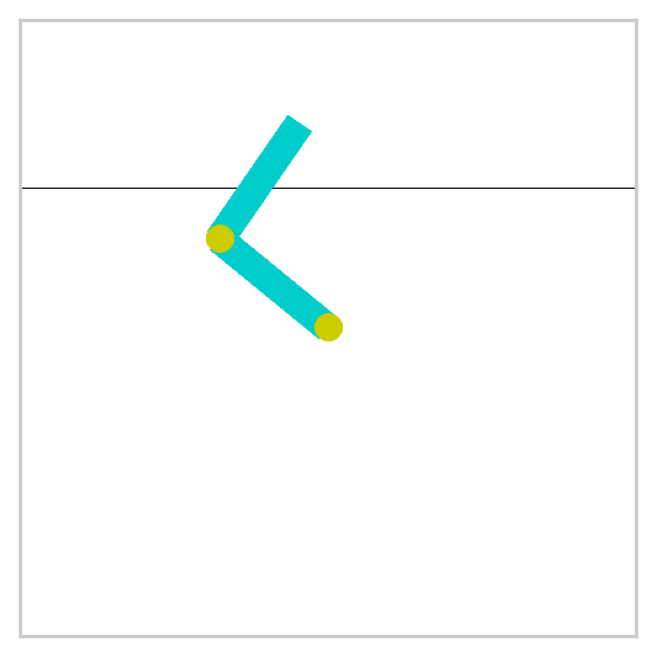

G_0 = -72.00 | шагов: 73

После обучения: Acrobot-v1 | Double DQN


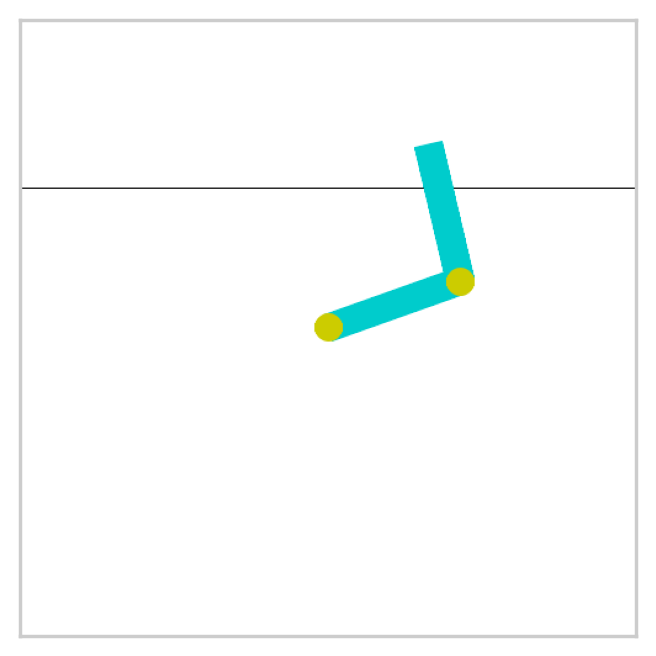

G_0 = -93.00 | шагов: 94

После обучения: LunarLander-v3 | Vanilla DQN


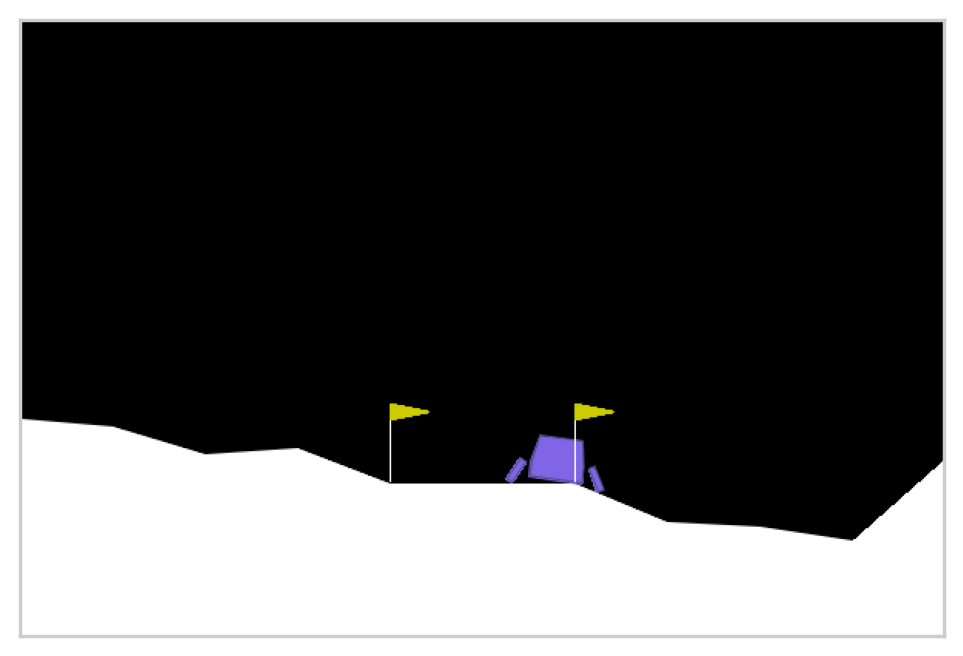

G_0 = 26.49 | шагов: 127

После обучения: LunarLander-v3 | Double DQN


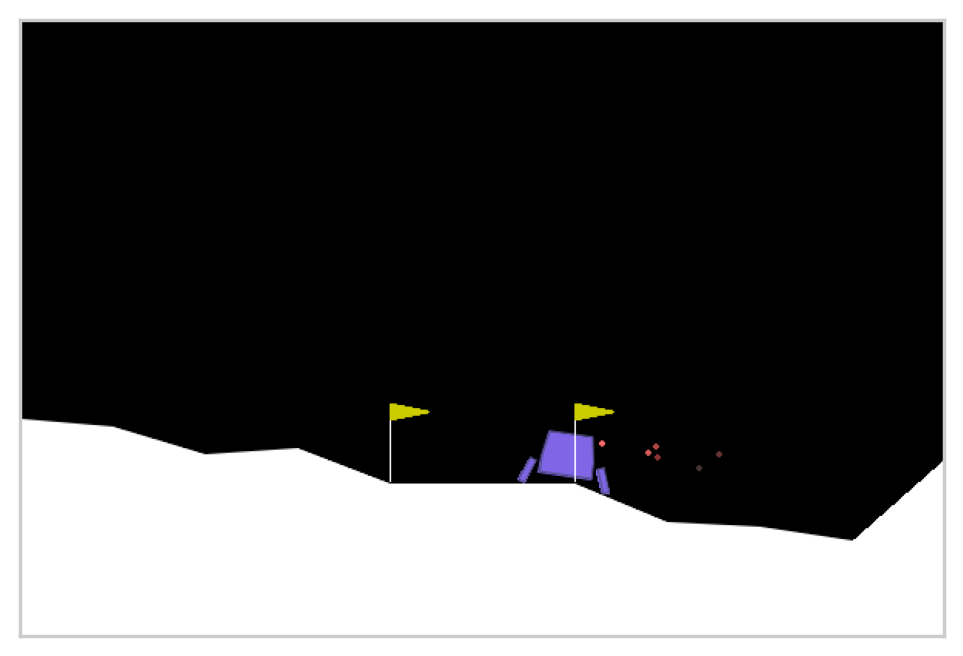

G_0 = 219.75 | шагов: 318



In [6]:
# Просмотр среды с обученными алгоритмами
for env_id, (results, window) in all_env_results.items():
    for res in results:
        print(f"После обучения: {env_id} | {res['name']}")
        env = gym.make(env_id, render_mode="rgb_array")
        state, info = env.reset(seed=SEED)
        episode_return = 0.0  # G_0
        episode_steps = 0

        fig, ax = plt.subplots(figsize=(6, 4))
        img = ax.imshow(env.render())
        ax.set_xticks([])
        ax.set_yticks([])

        display_handle = display.display(fig, display_id=True)

        for _ in range(1000):
            action = res["agent"].select_action(state, epsilon=0.0)
            state, reward, terminated, truncated, info = env.step(action)
            episode_return += reward
            episode_steps += 1
            
            img.set_data(env.render())
            display_handle.update(fig)
            
            if terminated or truncated:
                break

        plt.close(fig)
        env.close()
        print(f"G_0 = {episode_return:.2f} | шагов: {episode_steps}\n")